<a href="https://colab.research.google.com/github/deepakshet-tech/ML-code/blob/main/MLPROJECT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from datasets import load_dataset

In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion')

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
emotion_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [ ]:
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [ ]:
label_name = emotion_dataset['train'].features['label'].names
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
df_train = pd.DataFrame(
    {
        'text':  train_text,
        'label':[label_name[i] for i in train_label]
    }
)
df_test = pd.DataFrame(
    {
        'text':  test_text,
        'label':[label_name[i] for i in test_label]
    }
)

In [ ]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [ ]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df_train.isnull().sum()
df_test.isnull().sum()


,0
text,0
label,0


In [ ]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

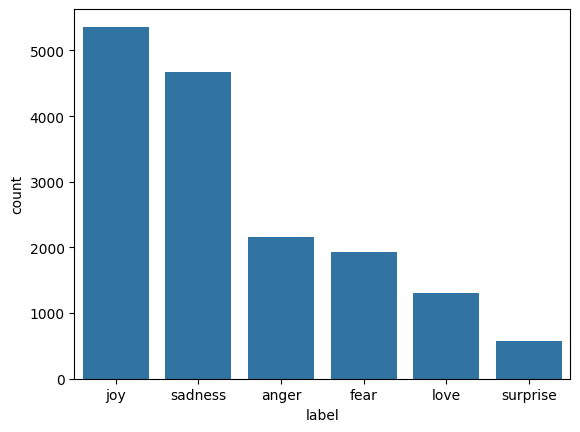

In [ ]:
sns.countplot(x = 'label',data = df_train, order =df_train['label'].value_counts().index)

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000
tokenizer =  Tokenizer(num_words = max_words, oov_token = '<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequences = pad_sequences(train_sequences, maxlen = 50, padding = 'post', truncating='post')
padded_test_sequences = pad_sequences(test_sequences, maxlen = 50, padding = 'post', truncating='post')

train_labels =np.array(train_label)
test_labels =np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"vacabulary size : { len(tokenizer.word_index)}")
print(f"Max Sentence Length :{padded_train_sequences.shape[1] }")

vacabulary size : 15213
Max Sentence Length :50


In [ ]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_labels),
    y = train_labels
)

class_weights_dict = dict(enumerate(class_weights))

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

earlystopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights = True
)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,LSTM,Embedding,GRU,Dense,Dropout

rnn_model = Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length = 50),
    SimpleRNN(units= 128,return_sequences = True),
    Dropout(0.5),
    SimpleRNN(units= 64),
    Dropout(0.5),
    Dense(units = num_classes,activation = 'softmax')
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
rnn_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[earlystopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 66ms/step - accuracy: 0.1669 - loss: 2.0192 - val_accuracy: 0.1725 - val_loss: 1.7958
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 63ms/step - accuracy: 0.1571 - loss: 1.8861 - val_accuracy: 0.1380 - val_loss: 1.7610
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 77ms/step - accuracy: 0.1456 - loss: 1.8211 - val_accuracy: 0.0795 - val_loss: 1.8047
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 54ms/step - accuracy: 0.1299 - loss: 1.8081 - val_accuracy: 0.0385 - val_loss: 1.8798
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 63ms/step - accuracy: 0.1370 - loss: 1.8019 - val_accuracy: 0.2870 - val_loss: 1.7654
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 56ms/step - accuracy: 0.1425 - loss: 1.8025 - val_accuracy: 0.0330 - val_loss: 1.8042
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.1396 - loss: 1.7996 - val_accuracy: 0.1375 - val_loss: 1.7705
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.1380 - loss: 1.7610
RNN Loss: 1.7609

In [ ]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[earlystopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 71s 133ms/step - accuracy: 0.1492 - loss: 1.7952 - val_accuracy: 0.0335 - val_loss: 1.8048
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 80s 161ms/step - accuracy: 0.1460 - loss: 1.7935 - val_accuracy: 0.1475 - val_loss: 1.7815
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 71s 138ms/step - accuracy: 0.1483 - loss: 1.7909 - val_accuracy: 0.2170 - val_loss: 1.7820
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 66s 133ms/step - accuracy: 0.1928 - loss: 1.7570 - val_accuracy: 0.1230 - val_loss: 1.7285
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 132ms/step - accuracy: 0.3026 - loss: 1.4972 - val_accuracy: 0.3380 - val_loss: 1.3441
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 130ms/step - accuracy: 0.5307 - loss: 0.9567 - val_accuracy: 0.4200 - val_loss: 1.1361
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 66s 131ms/step - accuracy: 0.7087 - loss: 0.6410 - val_accuracy: 0.8410 - val_loss: 0.5362
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 68s 136ms/step - accuracy: 0.8539 - loss: 0

In [ ]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[earlystopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 62s 115ms/step - accuracy: 0.1506 - loss: 1.7966 - val_accuracy: 0.1405 - val_loss: 1.7904
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 56s 113ms/step - accuracy: 0.1682 - loss: 1.7955 - val_accuracy: 0.0795 - val_loss: 1.8271
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 115ms/step - accuracy: 0.1476 - loss: 1.7946 - val_accuracy: 0.1425 - val_loss: 1.7855
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 114ms/step - accuracy: 0.1517 - loss: 1.7937 - val_accuracy: 0.3455 - val_loss: 1.7746
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 56s 112ms/step - accuracy: 0.1772 - loss: 1.7916 - val_accuracy: 0.3460 - val_loss: 1.7658
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.1405 - loss: 1.7904
GRU Loss: 1.7903865575790405
GRU Accuracy: 0.1404999941587448


In [ ]:
result_df = pd.DataFrame(
    {
        'model':['RNN','LSTM','GRU'],
        'Loss':[rnn_loss,lstm_loss,gru_loss],
        'Accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy]
    }
).sort_values(by = 'Accuracy',ascending=False)

result_df

,model,Loss,Accuracy
1,LSTM,0.358357,0.9070
2,GRU,1.790387,0.1405
0,RNN,1.760972,0.1380


In [ ]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
BiGRU.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[earlystopping]
)
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequences, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 155s 310ms/step - accuracy: 0.9701 - loss: 0.0867 - val_accuracy: 0.9220 - val_loss: 0.2499
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 154s 308ms/step - accuracy: 0.9768 - loss: 0.0639 - val_accuracy: 0.9150 - val_loss: 0.3085
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 157s 314ms/step - accuracy: 0.9834 - loss: 0.0509 - val_accuracy: 0.9220 - val_loss: 0.2849
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 152s 305ms/step - accuracy: 0.9847 - loss: 0.0441 - val_accuracy: 0.9150 - val_loss: 0.3263
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 209s 319ms/step - accuracy: 0.9865 - loss: 0.0374 - val_accuracy: 0.9145 - val_loss: 0.3480
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.9220 - loss: 0.2499
BiGRU Loss: 0.2499450445175171
BiGRU Accuracy: 0.921999990940094


63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 156ms/step


<Axes: >

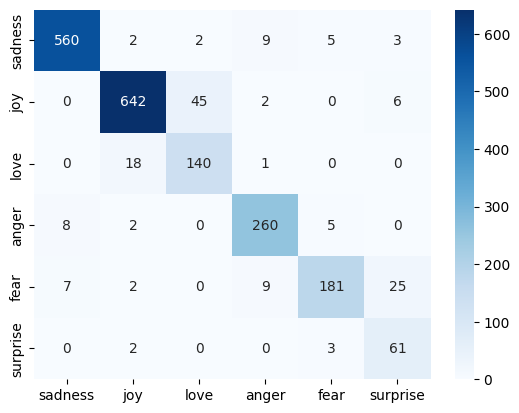

In [ ]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequences),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_name, yticklabels=label_name)
#

In [ ]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_predictions[i]]}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: anger
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [ ]:
import os
import pickle


model_dir = 'Artifacts'
os.makedirs(model_dir,exist_ok= True)

BiGRU.save(os.path.join(model_dir,'BiGRU_Model.keras'))

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb')as file:
  pickle.dump(tokenizer,file)